# Scrapping

In [2]:
import requests
import json
import pandas as pd
import time

def scrape_wynncraft_items():
    # Menambahkan parameter ?full_result untuk mengambil seluruh data (6000+ item)
    url = "https://api.wynncraft.com/v3/item/database?full_result"
    
    headers = {
        "User-Agent": "Mozilla/5.0",
        "Accept": "application/json"
    }

    print("Mengirim request ke server Wynncraft... (ini mungkin memakan waktu beberapa detik karena mengambil semua item)")
    response = requests.get(url, headers=headers)

    if response.status_code == 200:
        data = response.json() # Karena pakai full_result, bentuknya langsung berupa list of dictionaries
        
        # Save as JSON
        filename_json = "wynncraft_items_database.json"
        with open(filename_json, 'w', encoding='utf-8') as f:
            json.dump(data, f, ensure_ascii=False, indent=4)
            
        print(f"Scraping berhasil! {len(data)} item JSON disimpan ke {filename_json}")
        
        # Convert to CSV
        df = pd.json_normalize(data)
        
        filename_csv = "wynncraft_items.csv"
        df.to_csv(filename_csv, index=False)
        print(f"Data berhasil dikonversi menjadi CSV dan disimpan ke {filename_csv}")
        
        print("\nContoh 5 baris pertama data:")
        display(df.head())
            
    else:
        print(f"Gagal melakukan scraping. HTTP Status Code: {response.status_code}")
        print(f"Pesan dari server: {response.text}")

if __name__ == "__main__":
    scrape_wynncraft_items()


Mengirim request ke server Wynncraft... (ini mungkin memakan waktu beberapa detik karena mengambil semua item)
Scraping berhasil! 6725 item JSON disimpan ke wynncraft_items_database.json
Data berhasil dikonversi menjadi CSV dan disimpan ke wynncraft_items.csv

Contoh 5 baris pertama data:


,displayName,internalName,type,subType,emblem,tier,restriction,dropRestriction,elements,lore,...,icon.value.customModelData,majorIds.Fright or Flight,majorIds.Power Fist,identifications.fireSpellDamage,majorIds.Fan the Hammer,majorIds.Astrobleme,majorIds.Cannulate,majorIds.Snowy Steps,majorIds.Overwhelm,majorIds.Festive Spirit
0,Alstroemania,Alstroemania,armour,leggings,shield_6,legendary,none,normal,"[earth, thunder]",<span class='font-ascii' style='color:#AAAAAA'...,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Amalgamation,Amalgamation,weapon,wand,diamond_6,rare,none,normal,"[earth, thunder, water, fire, air]",NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Arbiter of Iridescence,Arbiter of Iridescence,accessory,necklace,sticker_6,fabled,none,never,"[earth, thunder, water, fire, air]",<span class='font-ascii' style='color:#AAAAAA'...,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Blacklight,Blacklight,weapon,dagger,diamond_6,unique,none,normal,"[thunder, air]",NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,Bleeding Soles,Bleeding Soles,armour,boots,shield_6,unique,none,normal,[fire],NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## Tugas 2: Import dan Pemahaman Dataset

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('wynncraft_items.csv')

display(df.head())

df.info()

print(f"\nShape dari dataset: {df.shape} (Baris, Kolom)")

display(df.dtypes.head(15)) # Menampilkan 15 pertama agar tidak terlalu panjang

/tmp/ipykernel_38542/1800401619.py:6: DtypeWarning: Columns (182: majorIds.Ignition Whirlwind, 195: majorIds.Vivid Dreamscapes, 208: majorIds.Self-sufficient, 236: majorIds.Burnt Shadows, 265: majorIds.Old Spark, 279: majorIds.Clamber, 289: majorIds.Flight Burst, 296: majorIds.Final Gambit, 300: majorIds.Last Resort, 328: majorIds.Faustian Gambit, 332: majorIds.Death Sentence, 333: majorIds.Dauntless Inferno, 334: majorIds.Geocentrism, 340: majorIds.Superconductor, 347: majorIds.Strings of Fate, 355: majorIds.Uncertainty Principle, 360: majorIds.Slow Boil, 365: majorIds.Blinding Lights, 367: majorIds.Seeking Module, 376: majorIds.Intangible, 377: majorIds.Orbwalk, 388: majorIds.Tackle, 393: majorIds.Disassociate, 404: majorIds.Solar Wind, 405: majorIds.Flain Remnants, 409: majorIds.Desperate Measures, 410: majorIds.Brachiate, 411: majorIds.Mob Mentality, 412: majorIds.Furious Effigy, 413: majorIds.Manic Edge, 414: majorIds.Stagnant Air, 424: majorIds.Bound by Blood, 427: majorIds.Lunge

,displayName,internalName,type,subType,emblem,tier,restriction,dropRestriction,elements,lore,...,icon.value.customModelData,majorIds.Fright or Flight,majorIds.Power Fist,identifications.fireSpellDamage,majorIds.Fan the Hammer,majorIds.Astrobleme,majorIds.Cannulate,majorIds.Snowy Steps,majorIds.Overwhelm,majorIds.Festive Spirit
0,Alstroemania,Alstroemania,armour,leggings,shield_6,legendary,none,normal,"['earth', 'thunder']",<span class='font-ascii' style='color:#AAAAAA'...,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Amalgamation,Amalgamation,weapon,wand,diamond_6,rare,none,normal,"['earth', 'thunder', 'water', 'fire', 'air']",NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Arbiter of Iridescence,Arbiter of Iridescence,accessory,necklace,sticker_6,fabled,none,never,"['earth', 'thunder', 'water', 'fire', 'air']",<span class='font-ascii' style='color:#AAAAAA'...,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Blacklight,Blacklight,weapon,dagger,diamond_6,unique,none,normal,"['thunder', 'air']",NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,Bleeding Soles,Bleeding Soles,armour,boots,shield_6,unique,none,normal,['fire'],NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


<class 'pandas.DataFrame'>
RangeIndex: 6725 entries, 0 to 6724
Columns: 630 entries, displayName to majorIds.Festive Spirit
dtypes: float64(436), int64(1), object(2), str(191)
memory usage: 32.3+ MB

Shape dari dataset: (6725, 630) (Baris, Kolom)


displayName                                   str
internalName                                  str
type                                          str
subType                                       str
emblem                                        str
tier                                          str
restriction                                   str
dropRestriction                               str
elements                                      str
lore                                          str
icon.value.id                                 str
icon.value.name                               str
icon.value.customModelData.rangeDispatch      str
icon.format                                   str
requirements.level                          int64
dtype: object

### Identifikasi Tipe Atribut
Berdasarkan eksplorasi di atas, kita bisa mengidentifikasi tipe dari beberapa atribut penting:
*   **Nominal**: `type`, `subType`, `dropRestriction` (kategori tanpa urutan hierarki yang pasti)
*   **Ordinal**: `tier` (memiliki tingkatan kelangkaan: Normal < Unique < Rare < Legendary < Fabled < Mythic)
*   **Numerik Diskrit**: `requirements.level`, `requirements.strength`, `requirements.dexterity` (poin level tidak dalam desimal)
*   **Numerik Kontinu**: `base.baseHealth`, atribut *damage* (meski di game berupa integer bulat, dalam kalkulasi statistik bisa dianggap rasio kontinu)

## Tugas 3: Analisis Statistik dan Kualitas Data

In [4]:
# 1. Statistik Deskriptif Atribut Numerik
display(df[['requirements.level', 'base.baseHealth', 'requirements.strength', 'requirements.dexterity']].describe())

# 2. Frekuensi Atribut Kategorikal
display(df['tier'].value_counts())

display(df['type'].value_counts())

,requirements.level,base.baseHealth,requirements.strength,requirements.dexterity
count,6725.000000,2471.000000,1473.000000,1385.000000
mean,69.553309,1532.173209,36.128988,36.784116
std,33.283046,1562.482762,18.768098,19.215361
min,1.000000,-3500.000000,2.000000,2.000000
25%,42.000000,200.000000,20.000000,20.000000
50%,75.000000,1000.000000,35.000000,35.000000
75%,98.000000,2800.000000,50.000000,50.000000
max,120.000000,7500.000000,110.000000,120.000000


tier
unique       2071
rare         1640
legendary     948
normal        481
fabled        374
TIER_2        294
TIER_1        250
TIER_0        233
TIER_3        195
mythic        127
Name: count, dtype: int64

type
weapon        2390
armour        2099
ingredient     972
accessory      924
tome           172
material       112
tool            52
charm            4
Name: count, dtype: int64

In [5]:
# 3. Identifikasi Nilai yang Hilang (Missing Values)
# Menghitung persentase agar lebih mudah dipahami
missing_percentages = (df.isnull().sum() / len(df)) * 100
display(missing_percentages.sort_values(ascending=False).head(10))



identifications.neutralMainAttackDamage.raw    99.98513
majorIds.Festive Spirit                        99.98513
majorIds.Pirouette                             99.98513
majorIds.Vedette                               99.98513
majorIds.Twisting Threads                      99.98513
majorIds.Lifestream                            99.98513
majorIds.Fixate                                99.98513
majorIds.Spectral Memory                       99.98513
majorIds.Efflorescence                         99.98513
majorIds.Chain Reaction                        99.98513
dtype: float64

In [6]:
# 4. Deteksi Outlier (Menggunakan IQR pada atribut requirements.level)
Q1 = df['requirements.level'].quantile(0.25)
Q3 = df['requirements.level'].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df[(df['requirements.level'] < lower_bound) | (df['requirements.level'] > upper_bound)]
print(f"Jumlah outlier pada requirements.level: {len(outliers)}")
# Jika hasilnya 0, berarti distribusi level tersebar merata dan tidak ada item dengan level req tidak masuk akal.

Jumlah outlier pada requirements.level: 0


## Tugas 4: Visualisasi Data

/tmp/ipykernel_38542/3082898776.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='tier', order=tier_order, ax=axes[1], palette='viridis')


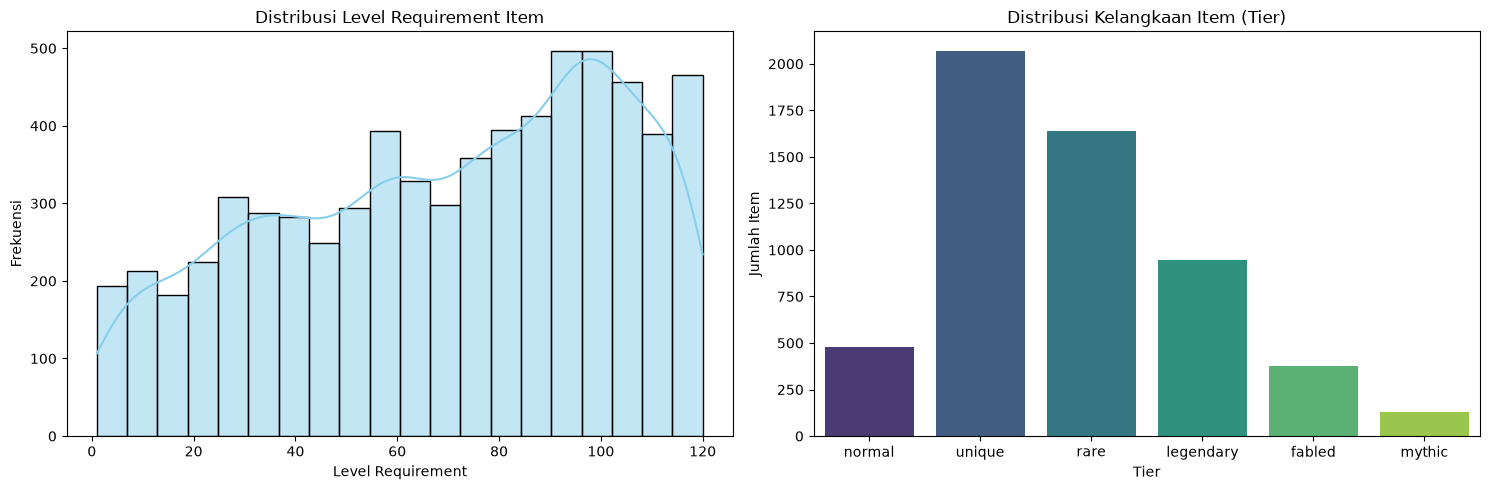

In [7]:
# 1. Univariat: Histogram & Bar Chart

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Histogram (Numerik)
sns.histplot(data=df, x='requirements.level', bins=20, kde=True, ax=axes[0], color='skyblue')
axes[0].set_title('Distribusi Level Requirement Item')
axes[0].set_xlabel('Level Requirement')
axes[0].set_ylabel('Frekuensi')

# Bar Chart (Kategorikal)
# Mengatur urutan tier dari yang terendah ke tertinggi
tier_order = ['normal', 'unique', 'rare', 'legendary', 'fabled', 'mythic']
sns.countplot(data=df, x='tier', order=tier_order, ax=axes[1], palette='viridis')
axes[1].set_title('Distribusi Kelangkaan Item (Tier)')
axes[1].set_xlabel('Tier')
axes[1].set_ylabel('Jumlah Item')

plt.tight_layout()
plt.show()

**Interpretasi Univariat:**
*   **Histogram Level**: Distribusi item menumpuk cukup tinggi di level-level awal (1-20) dan akhir (90-100). Ini menunjukkan game memiliki banyak *equipment* untuk pemula yang baru main, serta perlengkapan *end-game* untuk pemain pro.
*   **Bar Chart Tier**: Sebagian besar item di game berjenis *Unique* dan *Rare*. Item *Mythic* jumlahnya sangat sedikit, membuktikan kelangkaannya sesuai dengan desain game MMORPG.

/tmp/ipykernel_38542/2463948524.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='tier', y='requirements.level', order=tier_order, ax=axes[1], palette='Set2')


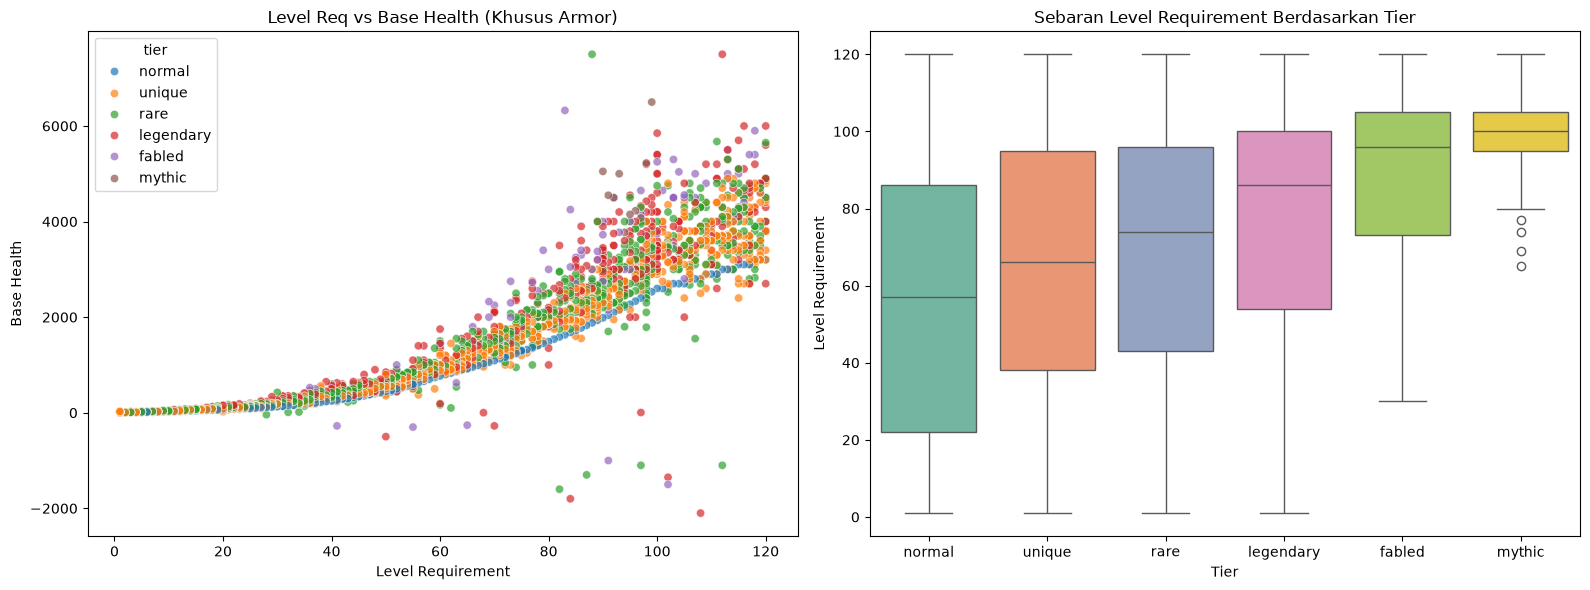

In [8]:
# 2. Bivariat: Boxplot dan Scatter Plot

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Scatter Plot (Numerik vs Numerik)
# Memfilter hanya tipe armor karena senjata tidak punya baseHealth
armor_df = df[df['type'] == 'armour']
sns.scatterplot(data=armor_df, x='requirements.level', y='base.baseHealth', hue='tier', alpha=0.7, ax=axes[0], hue_order=tier_order)
axes[0].set_title('Level Req vs Base Health (Khusus Armor)')
axes[0].set_xlabel('Level Requirement')
axes[0].set_ylabel('Base Health')

# Boxplot (Kategorikal vs Numerik)
sns.boxplot(data=df, x='tier', y='requirements.level', order=tier_order, ax=axes[1], palette='Set2')
axes[1].set_title('Sebaran Level Requirement Berdasarkan Tier')
axes[1].set_xlabel('Tier')
axes[1].set_ylabel('Level Requirement')

plt.tight_layout()
plt.show()

**Interpretasi Bivariat:**
*   **Scatter Plot**: Terlihat korelasi positif yang non-linear. Semakin tinggi level requirement, Health yang diberikan item naik secara eksponensial (melengkung ke atas), terutama untuk tier *Legendary* dan *Fabled*.
*   **Boxplot**: Item dengan rarity *Mythic* dan *Fabled* didominasi oleh level tinggi (median di atas level 80). Berbeda dengan *Unique* atau *Rare* yang tersebar luas dari level 1 hingga level 100.

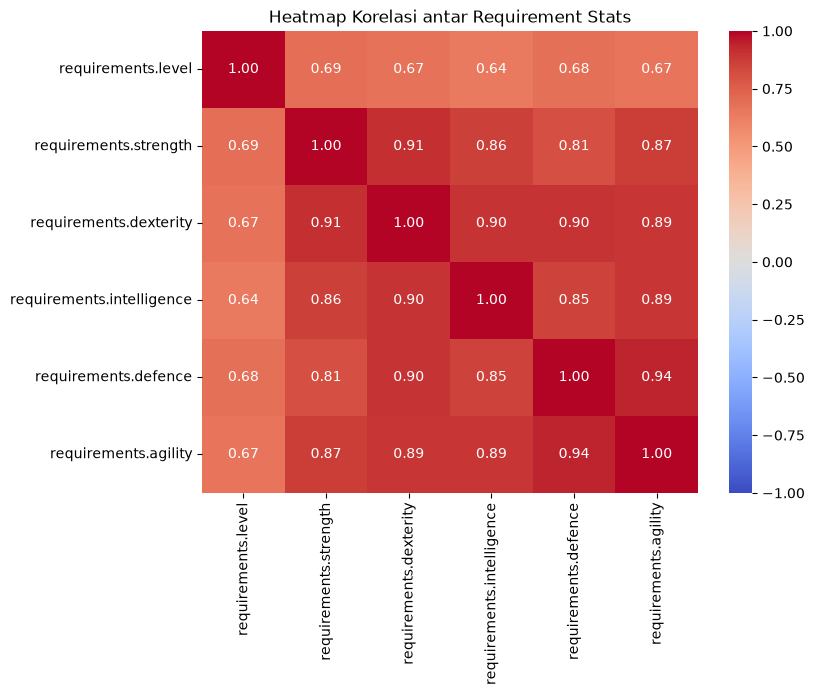

In [9]:
# 3. Bivariat/Multivariat: Correlation Heatmap
# Memilih beberapa kolom numerik yang relevan untuk dilihat korelasinya
numeric_cols = ['requirements.level', 'requirements.strength', 'requirements.dexterity', 
                'requirements.intelligence', 'requirements.defence', 'requirements.agility']

plt.figure(figsize=(8, 6))
correlation_matrix = df[numeric_cols].corr()
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', vmin=-1, vmax=1, fmt=".2f")
plt.title('Heatmap Korelasi antar Requirement Stats')
plt.show()

**Interpretasi Heatmap:**
*   Hampir semua *stat requirements* (Strength, Dex, dll) memiliki korelasi positif sedang dengan `requirements.level` (~0.4). Artinya wajar jika item level tinggi menuntut stat yang lebih besar.
*   Antar stat pendukung (seperti strength dengan dexterity) memiliki korelasi yang sangat rendah mendekati 0. Ini menandakan dalam sistem item game Wynncraft, sebuah *build* (susunan atribut pemain) biasanya fokus spesifik pada satu elemen saja, jarang ada item yang butuh stats tinggi di semua atribut sekaligus.